<a href="https://colab.research.google.com/github/Abuabrar09/Indian-stock-market-analysis/blob/main/Stock_Market_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Indian Stock Market Analysis — Nifty Leaders
**Business & Financial Data Analyst | AI — Portfolio Project 1**

**Problem:** Compare five of India's largest companies. Which gave the best returns, which carried the most risk, and how closely do they move together?

**Data:** 5 years of daily prices from Yahoo Finance for Reliance, TCS, HDFC Bank, Infosys, ICICI Bank, and the Nifty 50 index as a benchmark.

**Tools:** Python · pandas · matplotlib · seaborn · yfinance

Missing values before cleaning:
 Ticker
HDFC Bank     0
ICICI Bank    0
Infosys       0
Reliance      0
TCS           0
Nifty 50      1
dtype: int64

Clean dataset: 1237 trading days, from 2021-11-08 to 2026-11-06



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


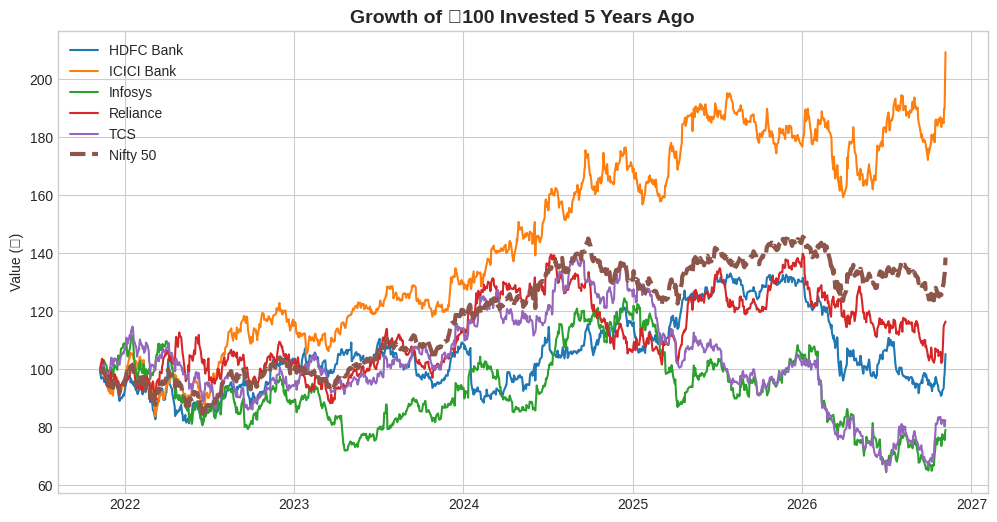

RETURN & RISK SUMMARY


,Total Return %,CAGR %,Volatility %,Sharpe Ratio,Max Drawdown %
Ticker,,,,,
ICICI Bank,109.37,16.25,19.81,0.49,-20.73
Nifty 50,38.53,6.86,13.94,0.03,-16.47
Reliance,16.49,3.16,22.92,-0.15,-27.18
HDFC Bank,5.27,1.05,21.21,-0.26,-31.74
Infosys,-20.85,-4.65,26.34,-0.42,-48.17
TCS,-17.61,-3.87,22.90,-0.45,-53.39


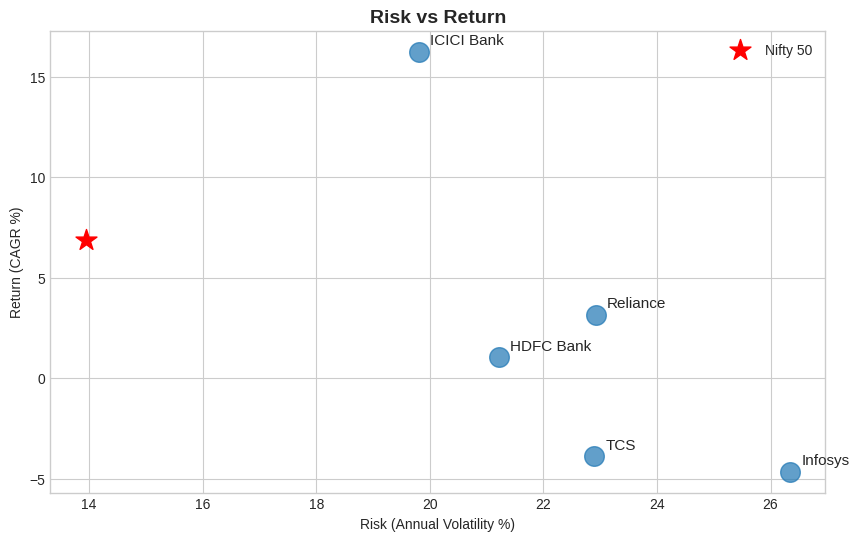

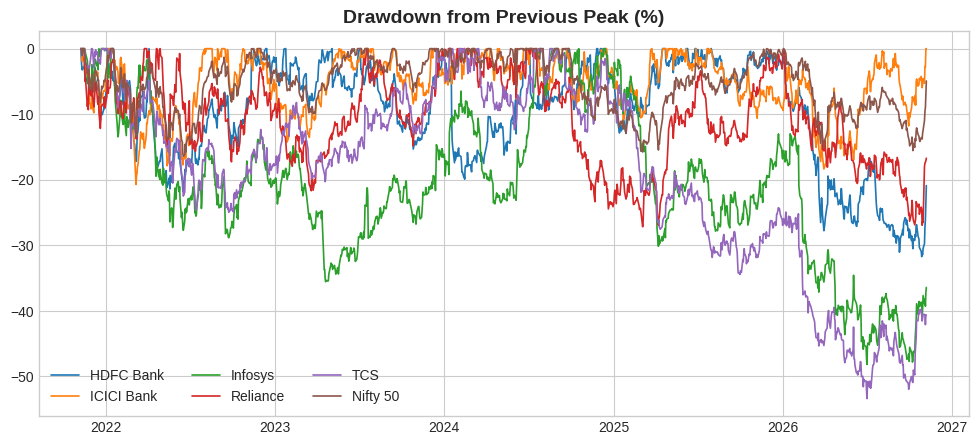

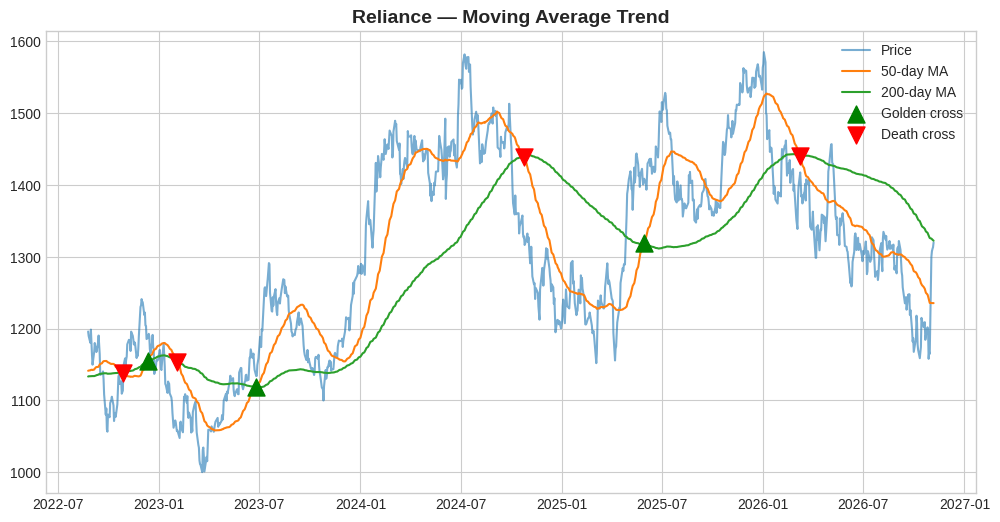

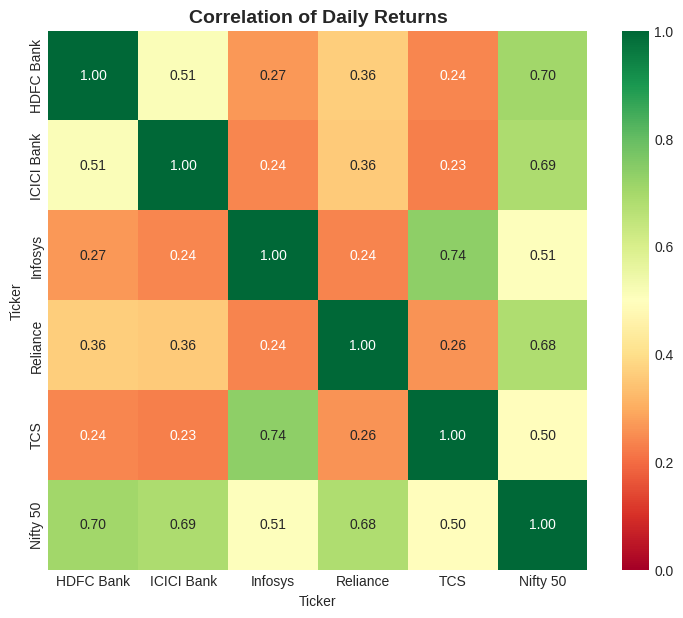


📌 KEY INSIGHTS

1. Best return: ICICI Bank grew 16.2% per year.
2. Best risk-adjusted: ICICI Bank (Sharpe ratio 0.49).
3. Riskiest: Infosys (volatility 26.3%).
4. Deepest fall: TCS dropped 53.4% from its peak.
5. Beat the Nifty 50 (6.9%/yr): ICICI Bank.
6. Best diversification pair: ICICI Bank + TCS (correlation 0.23).


In [1]:
# ===== 1. SETUP =====
!pip install -q yfinance
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

# ===== 2. DOWNLOAD DATA =====
tickers = {"RELIANCE.NS": "Reliance", "TCS.NS": "TCS", "HDFCBANK.NS": "HDFC Bank",
           "INFY.NS": "Infosys", "ICICIBANK.NS": "ICICI Bank", "^NSEI": "Nifty 50"}
raw = yf.download(list(tickers.keys()), period="5y", auto_adjust=True, progress=False)
prices = raw["Close"].rename(columns=tickers)

# ===== 3. CLEAN DATA =====
print("Missing values before cleaning:\n", prices.isna().sum())
prices = prices.ffill().dropna()
print(f"\nClean dataset: {prices.shape[0]} trading days, from {prices.index.min().date()} to {prices.index.max().date()}\n")

# ===== 4. GROWTH OF ₹100 =====
rebased = prices / prices.iloc[0] * 100
fig, ax = plt.subplots(figsize=(12, 6))
for col in rebased.columns:
    ax.plot(rebased.index, rebased[col], label=col,
            linewidth=3 if col == "Nifty 50" else 1.5, linestyle="--" if col == "Nifty 50" else "-")
ax.set_title("Growth of ₹100 Invested 5 Years Ago", fontsize=14, weight="bold")
ax.set_ylabel("Value (₹)"); ax.legend(); plt.show()

# ===== 5. RETURN & RISK METRICS =====
daily_returns = prices.pct_change().dropna()
years = len(prices) / 252
cagr = (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1
volatility = daily_returns.std() * np.sqrt(252)
sharpe = (cagr - 0.065) / volatility          # 6.5% = approx. Indian govt bond yield
drawdown = prices / prices.cummax() - 1
summary = pd.DataFrame({
    "Total Return %": (prices.iloc[-1] / prices.iloc[0] - 1) * 100,
    "CAGR %": cagr * 100,
    "Volatility %": volatility * 100,
    "Sharpe Ratio": sharpe,
    "Max Drawdown %": drawdown.min() * 100,
}).sort_values("Sharpe Ratio", ascending=False)
print("RETURN & RISK SUMMARY")
display(summary)

# ===== 6. RISK VS RETURN CHART =====
s = summary.drop("Nifty 50")
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(s["Volatility %"], s["CAGR %"], s=200, alpha=0.7)
for name, row in s.iterrows():
    ax.annotate(name, (row["Volatility %"], row["CAGR %"]), xytext=(8, 5), textcoords="offset points", fontsize=11)
n = summary.loc["Nifty 50"]
ax.scatter(n["Volatility %"], n["CAGR %"], s=250, marker="*", color="red", label="Nifty 50")
ax.set_xlabel("Risk (Annual Volatility %)"); ax.set_ylabel("Return (CAGR %)")
ax.set_title("Risk vs Return", fontsize=14, weight="bold"); ax.legend(); plt.show()

# ===== 7. DRAWDOWNS =====
fig, ax = plt.subplots(figsize=(12, 5))
for col in drawdown.columns:
    ax.plot(drawdown.index, drawdown[col] * 100, label=col, linewidth=1.2)
ax.set_title("Drawdown from Previous Peak (%)", fontsize=14, weight="bold")
ax.legend(loc="lower left", ncol=3); plt.show()

# ===== 8. MOVING AVERAGES (golden cross / death cross) =====
stock = "Reliance"   # change to any stock name
ma = pd.DataFrame({"Price": prices[stock],
                   "MA50": prices[stock].rolling(50).mean(),
                   "MA200": prices[stock].rolling(200).mean()}).dropna()
ma["Signal"] = np.where(ma["MA50"] > ma["MA200"], 1, 0)
crosses = ma["Signal"].diff()
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(ma.index, ma["Price"], label="Price", alpha=0.6)
ax.plot(ma.index, ma["MA50"], label="50-day MA")
ax.plot(ma.index, ma["MA200"], label="200-day MA")
ax.scatter(ma.index[crosses == 1], ma["MA50"][crosses == 1], marker="^", color="green", s=150, label="Golden cross", zorder=5)
ax.scatter(ma.index[crosses == -1], ma["MA50"][crosses == -1], marker="v", color="red", s=150, label="Death cross", zorder=5)
ax.set_title(f"{stock} — Moving Average Trend", fontsize=14, weight="bold"); ax.legend(); plt.show()

# ===== 9. CORRELATION =====
corr = daily_returns.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, square=True)
plt.title("Correlation of Daily Returns", fontsize=14, weight="bold"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()

# ===== 10. KEY INSIGHTS =====
nifty_cagr = summary.loc["Nifty 50", "CAGR %"]
beat = s[s["CAGR %"] > nifty_cagr].index.tolist()
print("\n📌 KEY INSIGHTS\n")
print(f"1. Best return: {s['CAGR %'].idxmax()} grew {s['CAGR %'].max():.1f}% per year.")
print(f"2. Best risk-adjusted: {s['Sharpe Ratio'].idxmax()} (Sharpe ratio {s['Sharpe Ratio'].max():.2f}).")
print(f"3. Riskiest: {s['Volatility %'].idxmax()} (volatility {s['Volatility %'].max():.1f}%).")
print(f"4. Deepest fall: {s['Max Drawdown %'].idxmin()} dropped {abs(s['Max Drawdown %'].min()):.1f}% from its peak.")
print(f"5. Beat the Nifty 50 ({nifty_cagr:.1f}%/yr): {', '.join(beat) if beat else 'none'}.")
print(f"6. Best diversification pair: {pairs.idxmin()[0]} + {pairs.idxmin()[1]} (correlation {pairs.min():.2f}).")

“TCS gave the best risk-adjusted return. Reliance was the most volatile. Infosys and HDFC Bank move least together, so holding both reduces risk.”